# EVENT SCATTER + MODEL CORRELATIONS — runnable copy

# Vegas and model accuracy: validation and test
Read only the selected `val` and `test` prediction exports, keeping splits separate.
Compare the market favorite with the model on the same eligible fights within each file.
Fair market probabilities are derived from `dec_fair_<stage>_red`.
Draws/no contests, missing outcomes, invalid dates, odds, or probabilities are excluded
and counted in the coverage table. Tied market odds select red, as in the old notebook.
F1 treats red as the positive class; lower Brier scores are better.

Return correlations below simulate the current saved policies from these same prediction
files, separately for validation and test. No legacy Kelly result files are required.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "pyproject.toml").is_file() and (folder / "src" / "ufc_betting").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting project.")
for folder in (project_root, project_root / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ufc_betting.config import settings
from Notebooks.Bets.vegas_accuracy_helpers import (
    load_accuracy_data, score_predictions, metrics_over_time,
    plot_accuracy, plot_accuracy_regression, event_accuracy_returns,
    plot_return_correlations, save_png, save_dataframe,
)


In [ ]:
splits = ("val", "test")
markets = ("open", "close1", "close2")
model_type = "open"
prediction_dir = settings.model_predictions_folder
prediction_template = "{split}_logit_{model_type}_with_{odds_type}.csv"


save_plots = True
plot_output_dir = settings.data_dir / "vegas_accuracy"
save_tables = True
results_output_dir = plot_output_dir / "tables"


In [3]:
data_dir = settings.project_root / "Data"
plot_output_dir = data_dir/ "images" / "plot_pngs"

def save_plot(fig, filename):
    path = plot_output_dir / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved plot: {path.resolve()}")
    return path


if not splits or not set(splits) <= {"val", "test"}:
    raise ValueError("Only val and test splits are supported here.")
datasets, coverage_rows, score_rows = {}, [], []
for split in splits:
    for market in markets:
        path = prediction_dir / prediction_template.format(
            split=split, model_type=model_type, odds_type=market)
        if not path.is_file():
            raise FileNotFoundError(f"Missing {split}/{market} predictions: {path}")
        data, coverage = load_accuracy_data(path, market)
        datasets[(split, market)] = data
        coverage_rows.append(dict(split=split, market=market, **coverage))
        for source in ("vegas", "model"):
            score_rows.append(dict(split=split, market=market, source=source,
                                   fights=len(data), **score_predictions(data, source)))
coverage = pd.DataFrame(coverage_rows)
summary = pd.DataFrame(score_rows)


## Validation results
Only `val` prediction files are used below.

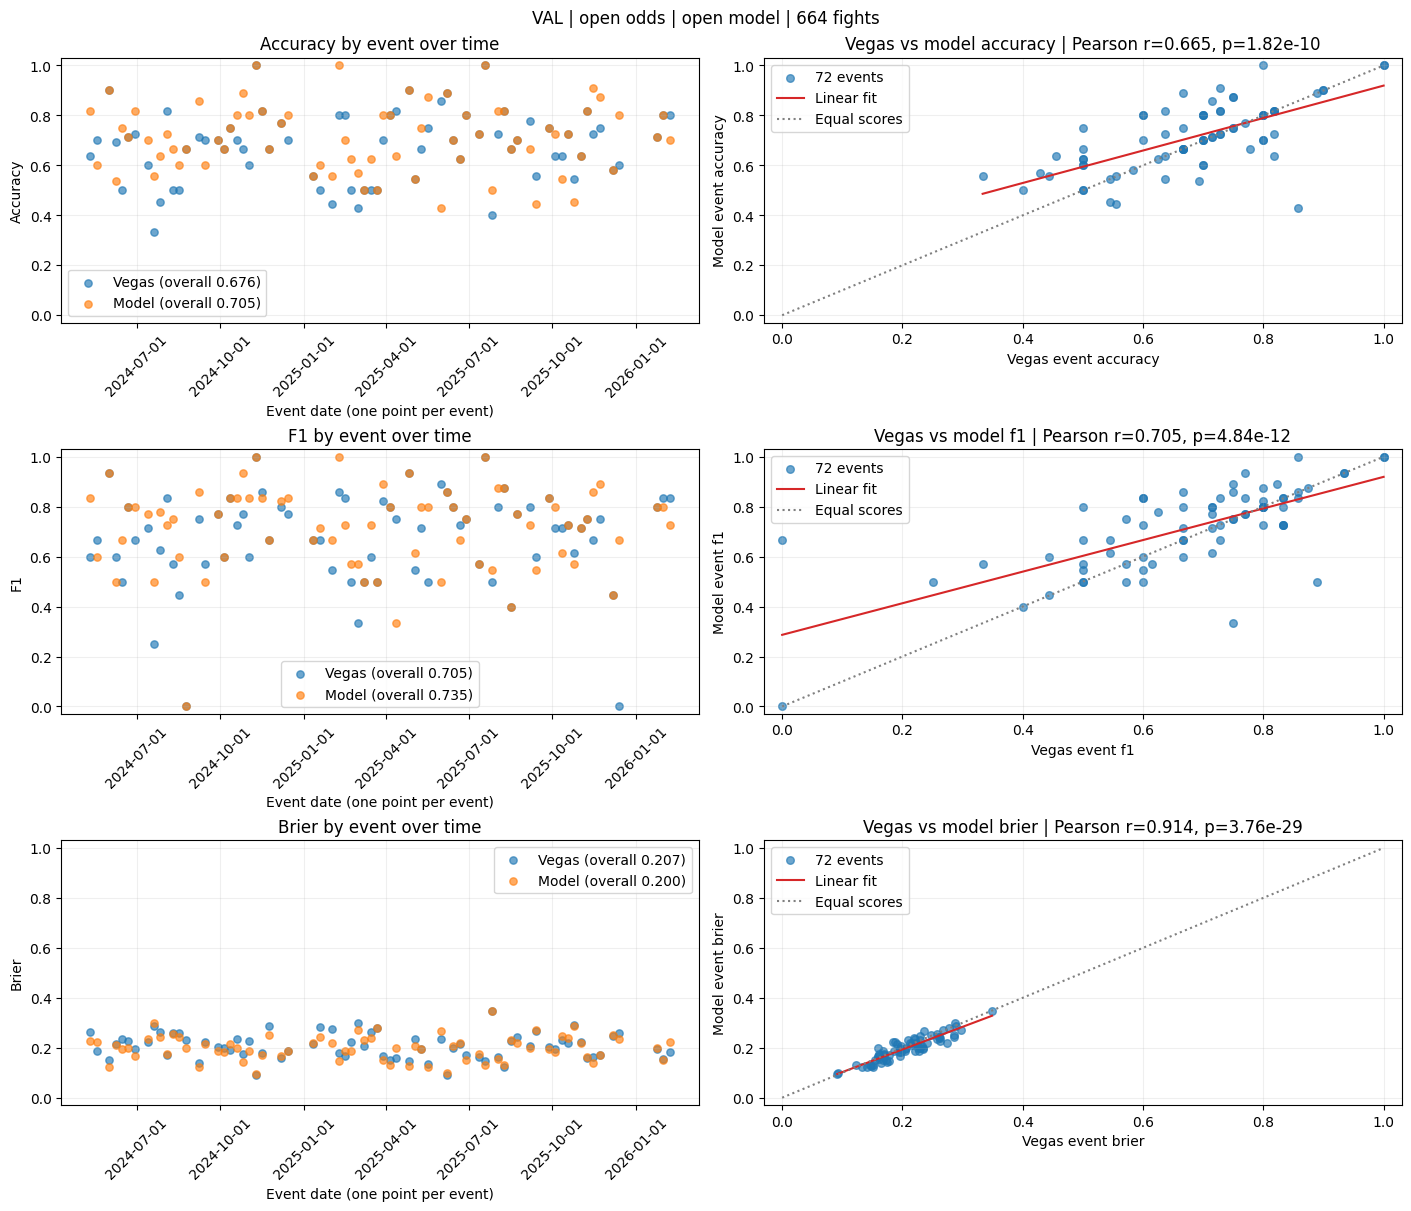

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_open_vegas.png


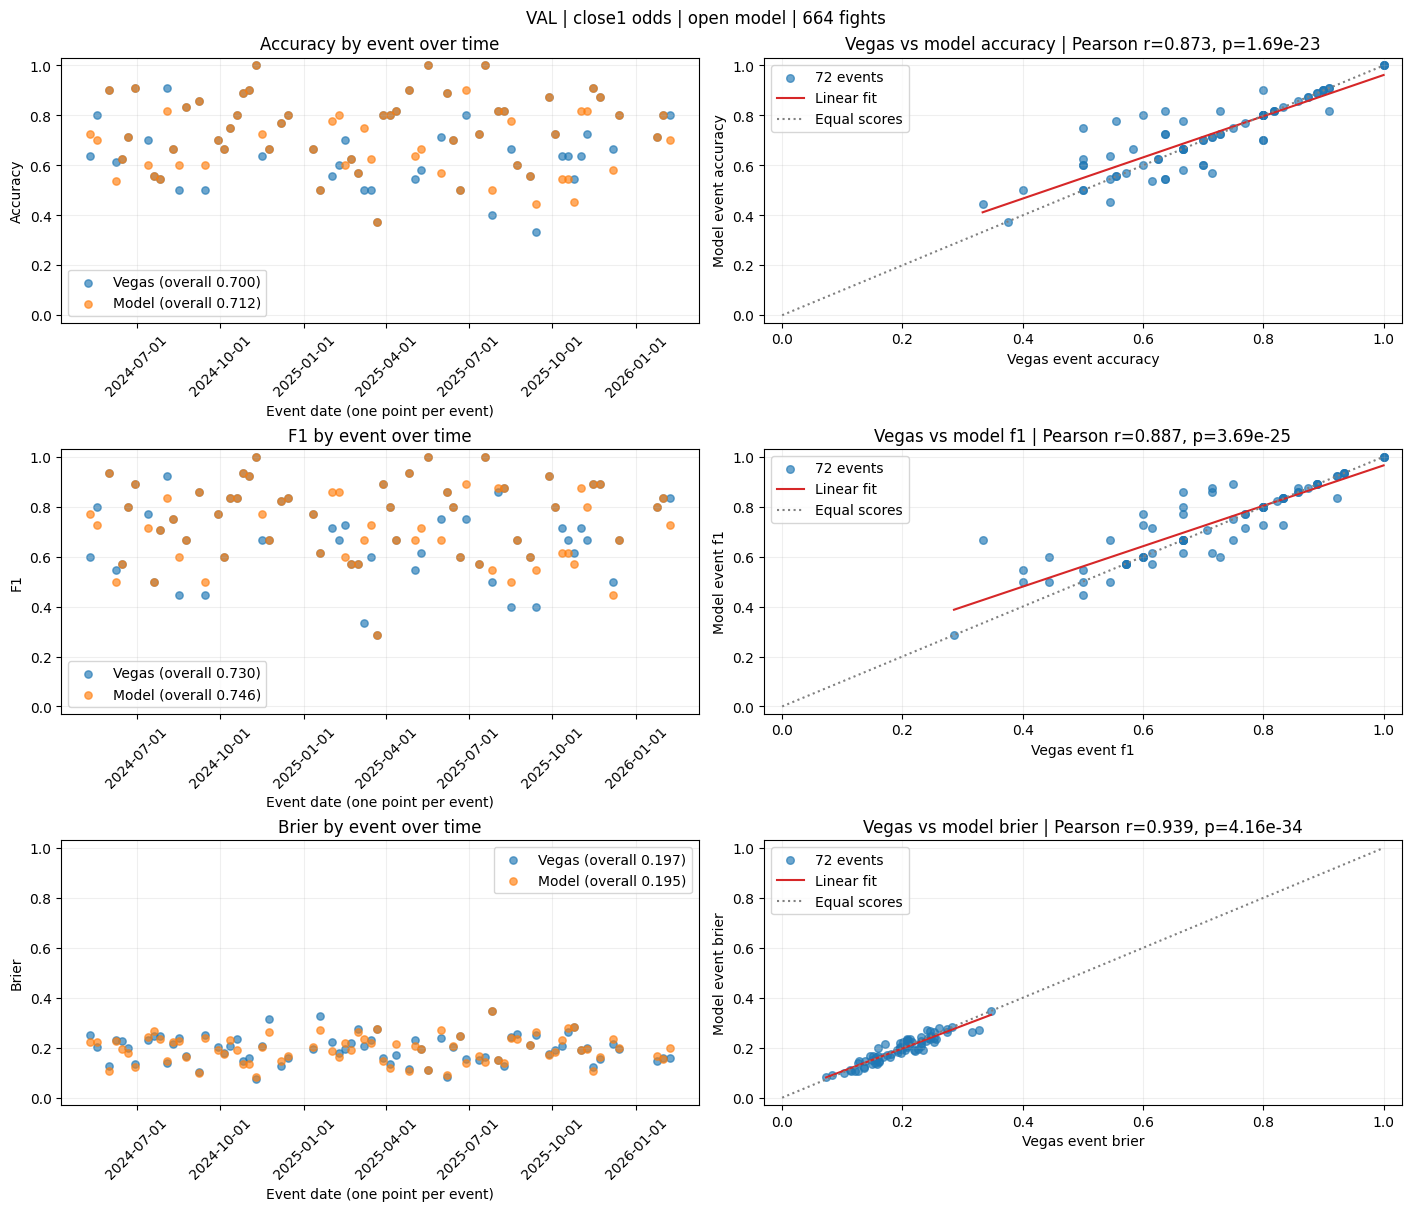

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_close1_vegas.png


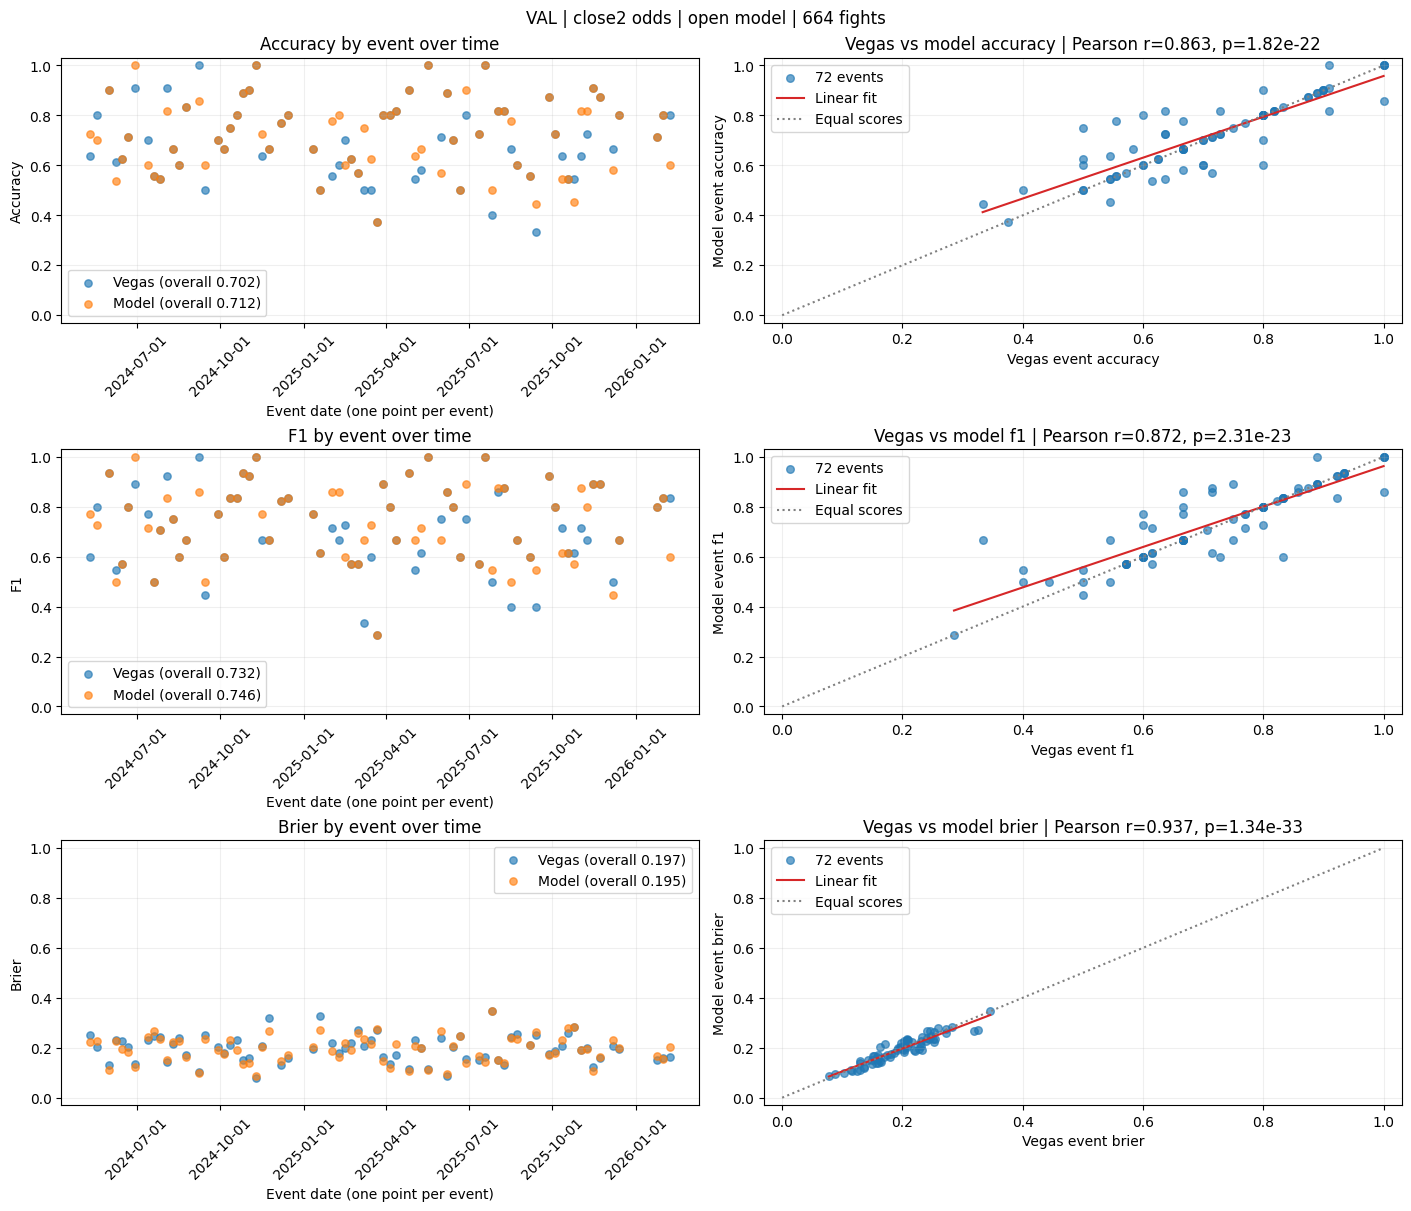

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_close2_vegas.png


In [4]:
validation_figures = {}
for market in markets:
    fig, trend = plot_accuracy(datasets[("val", market)], "val", market, model_type=model_type)
    validation_figures[market] = (fig, trend)
    display(fig)
    save_plot(fig, f"val_accuracy_{market}_vegas.png")
    plt.close(fig)


## Event accuracy regression: model accuracy on Vegas accuracy
For each split and market, fit `model_accuracy = constant + beta * vegas_accuracy`.
Each event has equal weight; accuracy is a fraction from 0 to 1. Vegas accuracy is
the only predictor. The plot includes the fitted line and 95% confidence band for
the mean. The coefficient table reports estimates, standard errors, t statistics,
two-sided p-values for H0: coefficient = 0, and 95% confidence intervals for both
constant and slope. These are ordinary OLS t-tests with n-2 residual degrees of
freedom (independent, homoskedastic errors); each split is fitted separately.
Pearson p-values above test zero correlation and are two-sided.

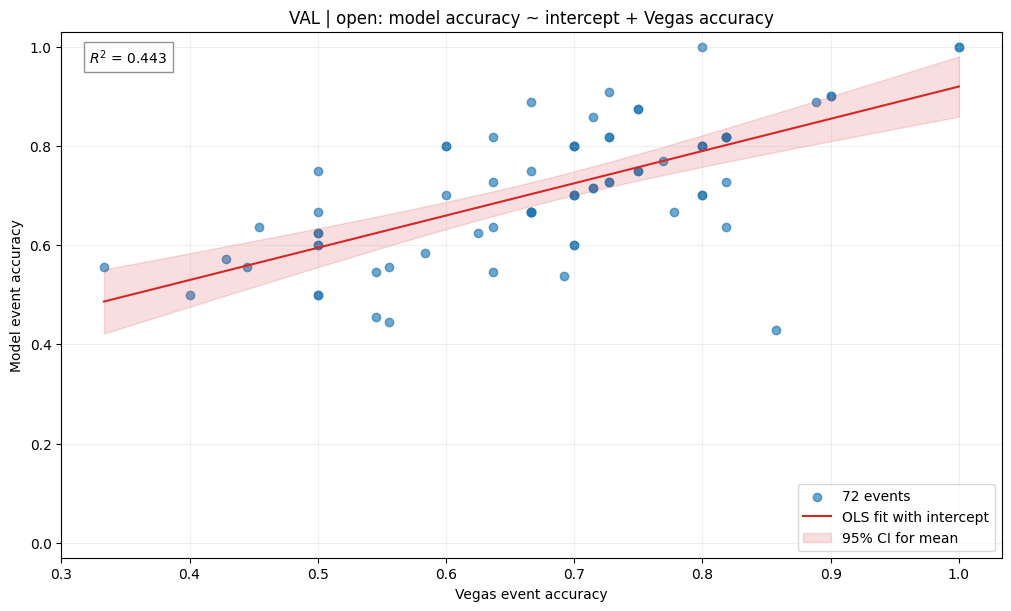

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_regression_open_vegas.png


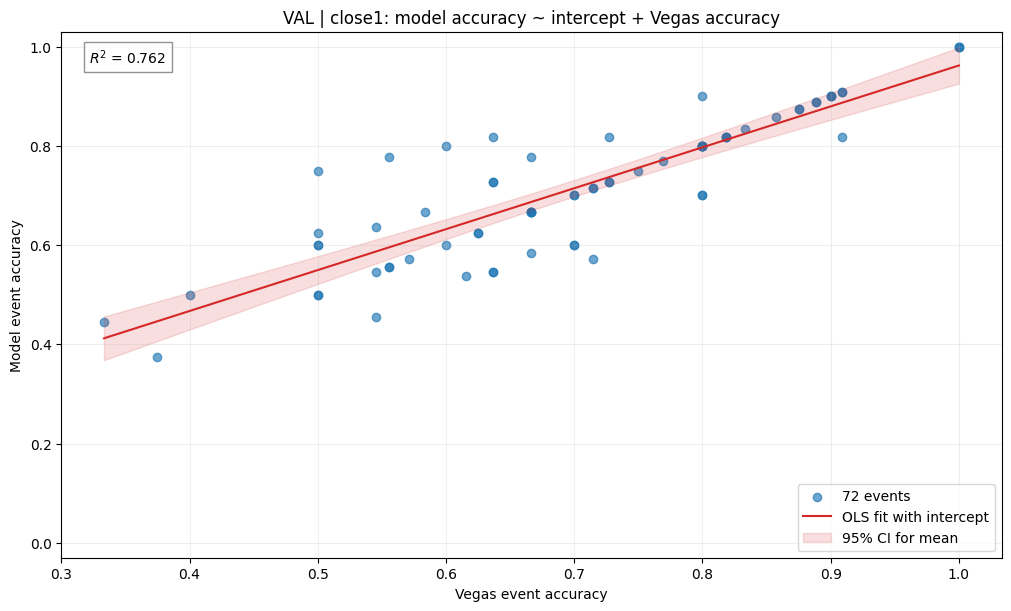

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_regression_close1_vegas.png


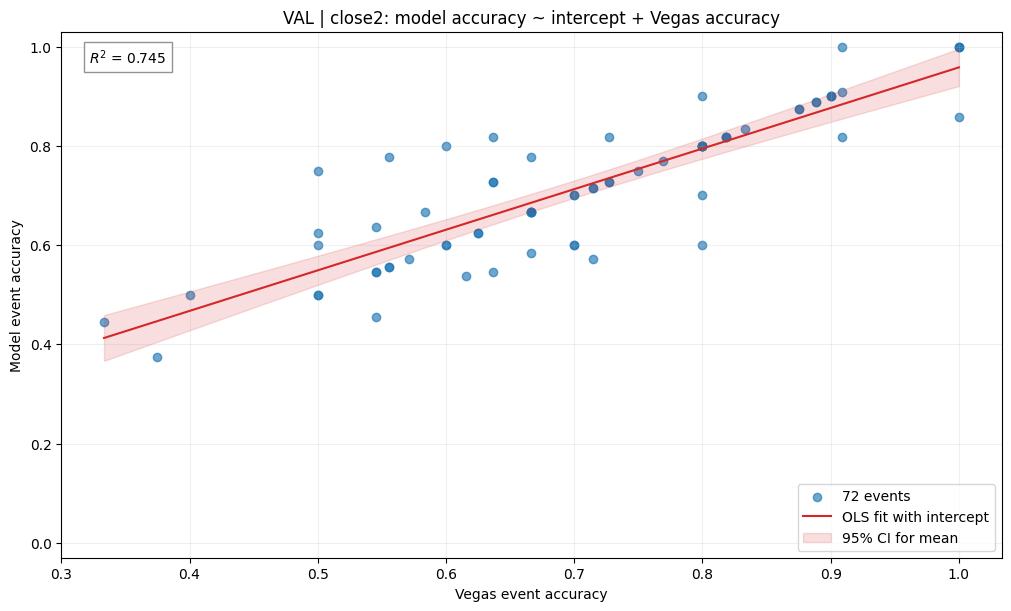

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\val_accuracy_regression_close2_vegas.png


coefficient  std_error  t_statistic  \
split market term                                                  
val   open   const              0.269589   0.060343     4.467650   
             vegas_accuracy     0.649900   0.087145     7.457671   
      close1 const              0.137276   0.039729     3.455310   
             vegas_accuracy     0.824609   0.055110    14.962916   
      close2 const              0.140103   0.041367     3.386863   
             vegas_accuracy     0.817971   0.057178    14.305803   

                                  p_value significance  ci_95_low  ci_95_high  
split market term                                                              
val   open   const           2.967618e-05          ***   0.149240    0.389939  
             vegas_accuracy  1.816437e-10          ***   0.476094    0.823705  
      close1 const           9.379045e-04          ***   0.058039    0.216513  
             vegas_accuracy  1.686832e-23          ***   0.714695    0.934523  
      close2 const           1.163231e-03           **   0.057600    0.222606  
             vegas_accuracy  1.821777e-22          ***   0.703934    0.932008

In [6]:

accuracy_regressions, coefficient_tables, regression_figures = {}, {}, {}
for market in markets:
    key = ('val', market)
    fit, coefficients, fig = plot_accuracy_regression(datasets[key], 'val', market)
    accuracy_regressions[key] = fit
    coefficient_tables[key] = coefficients
    regression_figures[key] = fig
    display(fig)
    save_plot(fig, f"val_accuracy_regression_{market}_vegas.png")
    plt.close(fig)

regression_coefficients = pd.concat(coefficient_tables, names=["split", "market", "term"])
display(regression_coefficients)
regression_coefficients.to_csv(settings.data_dir / "backtest_results" / f"regression_coefficients_{model_type}_vegas.csv", index=True)

## Event accuracy versus strategy returns
Each point is one event date. The x-axis is Vegas accuracy across eligible decided
fights in that event; the y-axis is realized profit as a percentage of event-start
bankroll. The moneyline panel restores the original correlation analysis; additional
panels show parlay and combined returns. Ticket profit is counted once per event.
No-bet events remain at zero; events starting with a nonpositive bankroll are excluded.
Pearson r and a fitted line are shown when both variables vary. Validation and test
are evaluated separately with the saved policies, without fitting new parameters.

In [ ]:

initial_bankroll = 500
use_decay = True  # Applies to close1/close2; opening always has decay disabled.


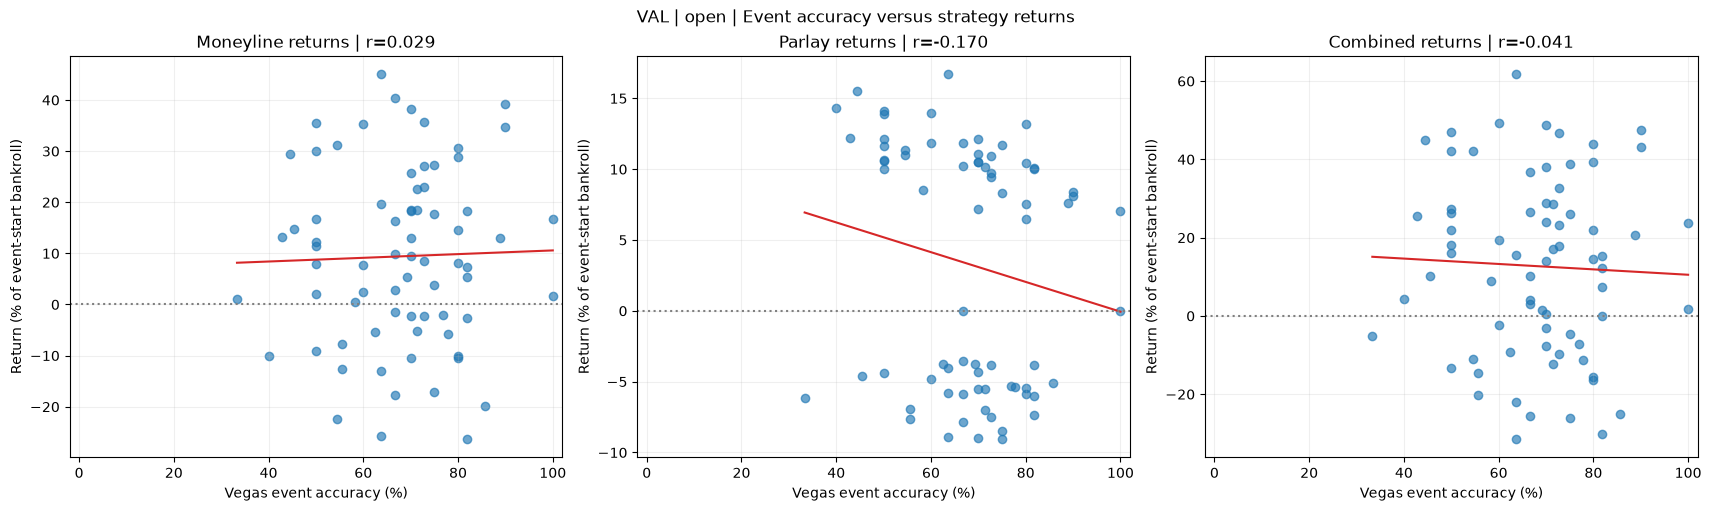

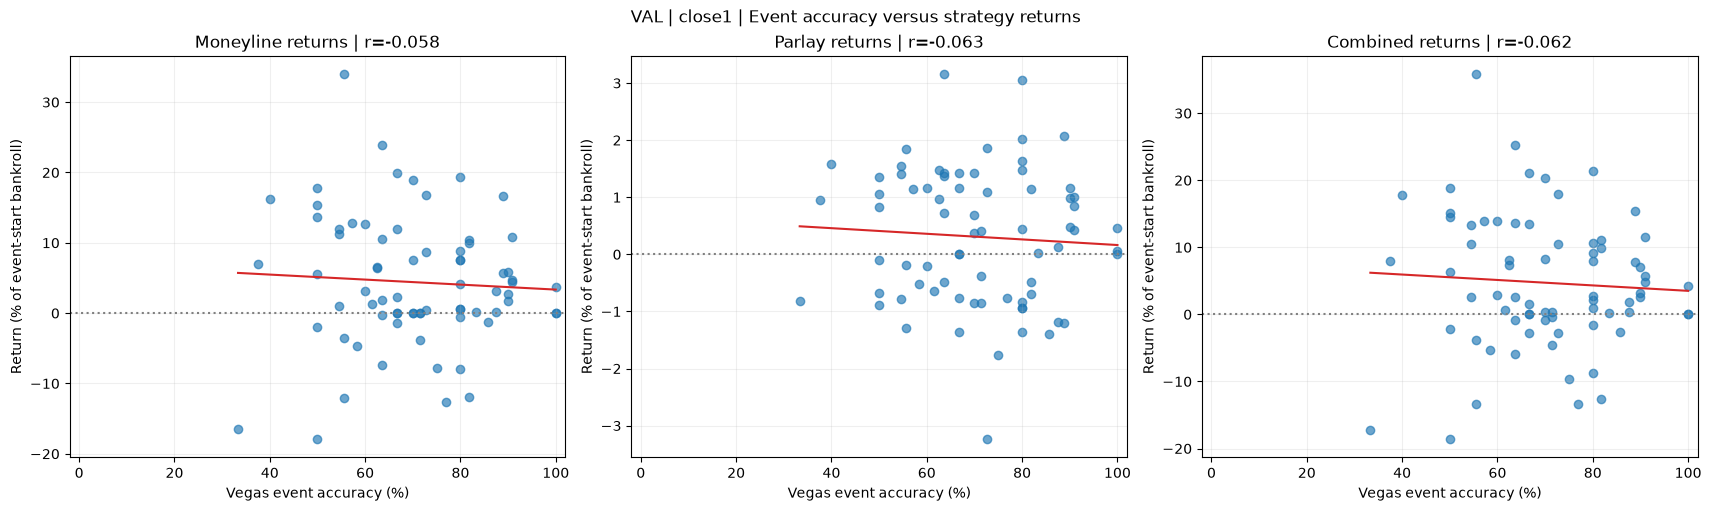

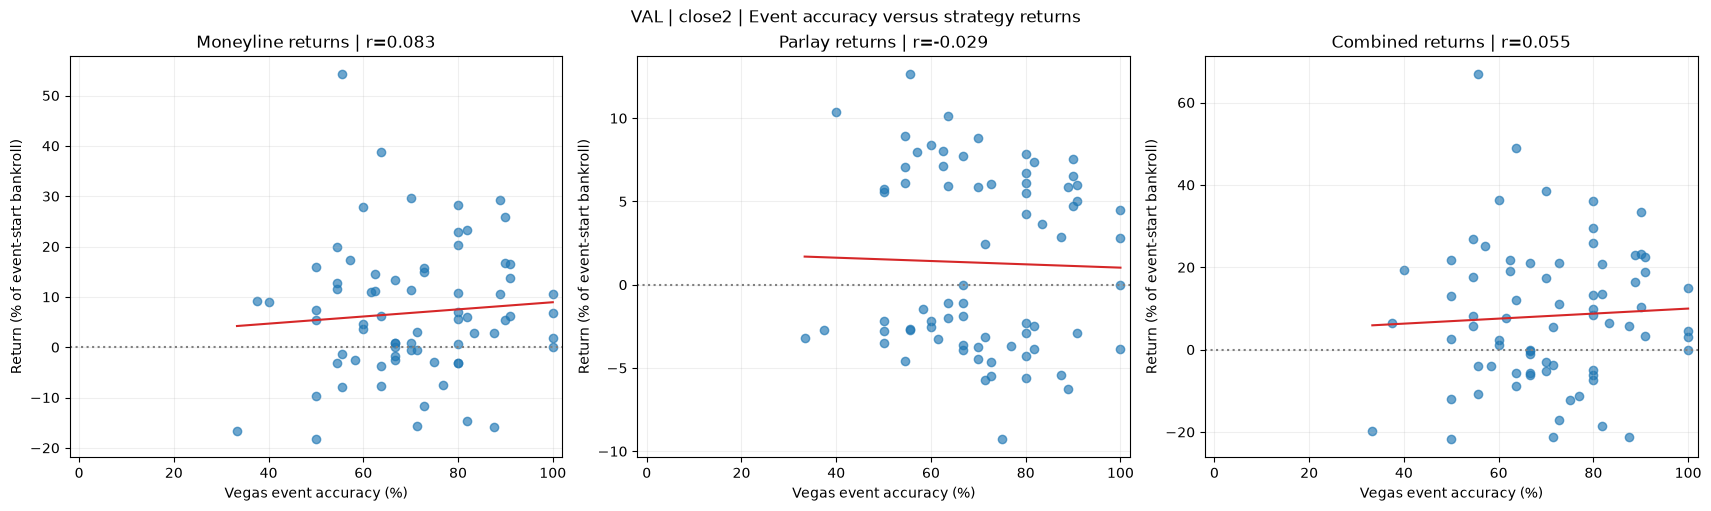

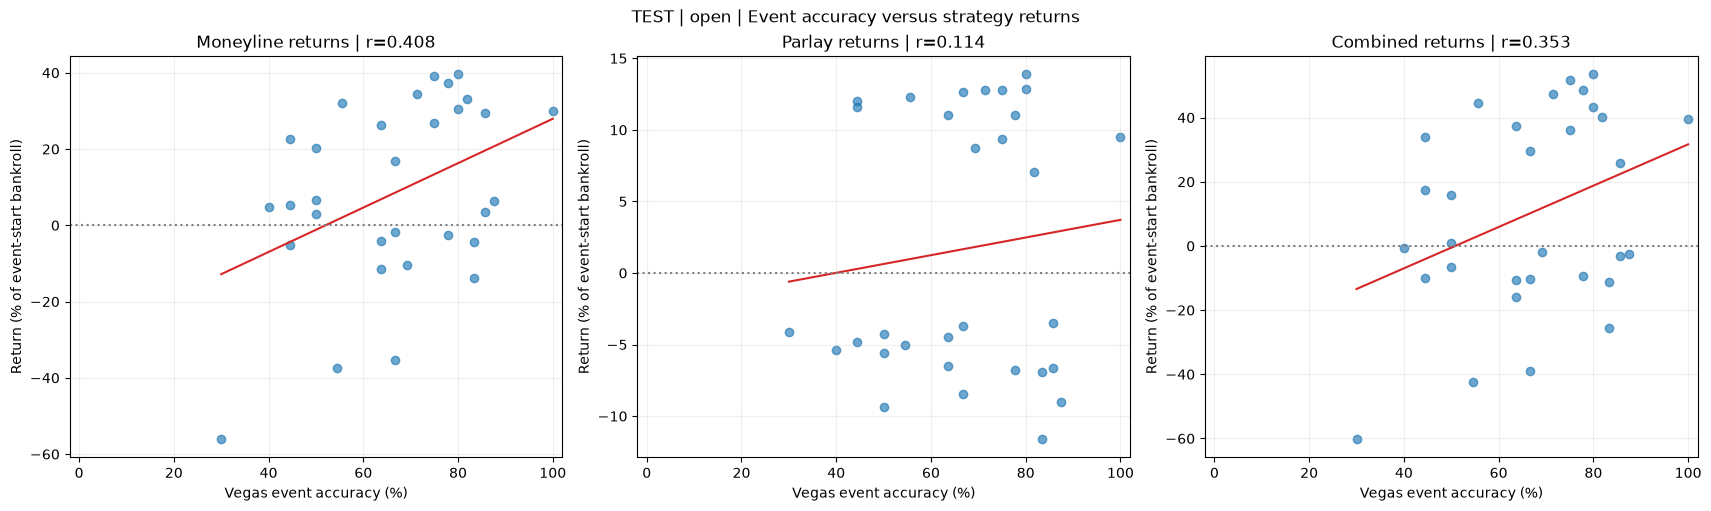

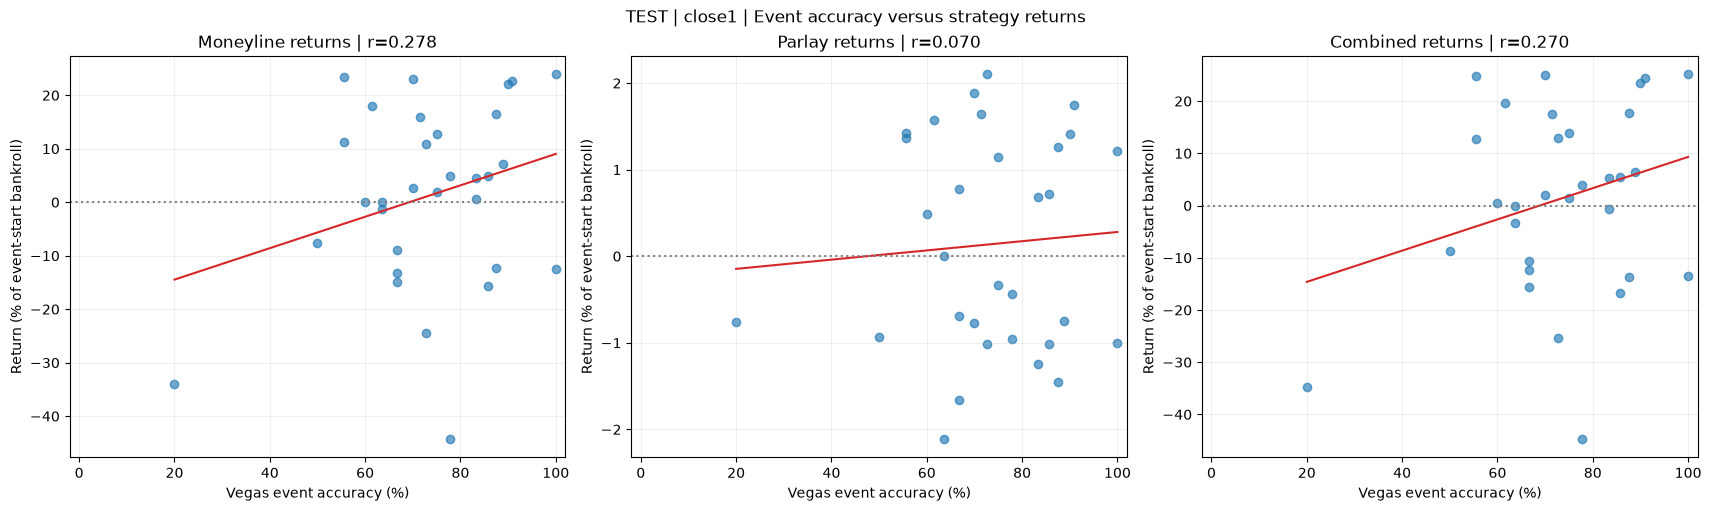

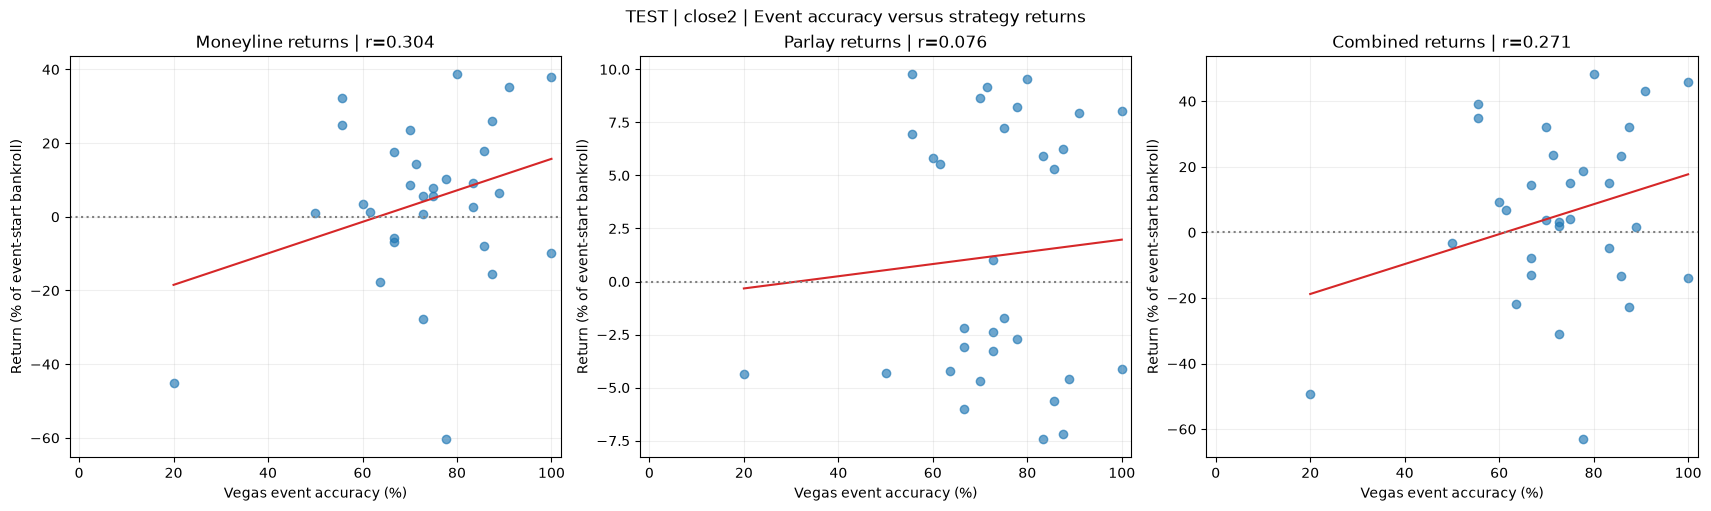

,split,market,family,events,pearson_r
0,val,open,moneyline,72,0.0286
1,val,open,parlay,72,-0.1703
2,val,open,combined,72,-0.0413
3,val,close1,moneyline,72,-0.0581
4,val,close1,parlay,72,-0.0627
5,val,close1,combined,72,-0.0616
6,val,close2,moneyline,72,0.0826
7,val,close2,parlay,72,-0.0288
8,val,close2,combined,72,0.0547
9,test,open,moneyline,31,0.4079


In [8]:
event_results, simulation_results, correlation_figures = {}, {}, {}
correlation_rows = []
for split in splits:
    for market in markets:
        events, moneylines, parlays = event_accuracy_returns(
            datasets[(split, market)], market, initial_bankroll=initial_bankroll, use_decay=use_decay
        )
        event_results[(split, market)] = events
        simulation_results[(split, market)] = (moneylines, parlays)
        fig, rows = plot_return_correlations(events, split, market)
        correlation_figures[(split, market)] = fig
        display(fig)
        plt.close(fig)
        correlation_rows.extend(rows)
correlation_summary = pd.DataFrame(correlation_rows)
display(correlation_summary.round(4))

## Save figures and regression results
Run after the analysis cells. Set `save_plots`, `save_tables`, and the output folders
above. Saving is separate from plotting; returned figures remain available even
after display. CSVs preserve split, market, and coefficient term identifiers.
To save one result directly: `save_png(regression_figures[("val", "open")], plot_output_dir / "my_regression.png")`
or `save_dataframe(coefficient_tables[("val", "open")], results_output_dir / "my_coefficients.csv")`.